In [1]:
import json

from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

from emu_renewal.constants import DATA_PATH, FULL_RUN, OXCGRT_COLMAP
from emu_renewal.outputs import get_policy_weight_summary
from emu_renewal.plotting import plot_manuscript_policy_weights
from emu_renewal.utils import get_analysis_paths, get_countries_by_continent

set_matplotlib_formats("svg")

In [2]:
B_THRESH = 1.0

all_countries = json.load(open(DATA_PATH / "config/oxcgrt_included.json"))
analysis_paths = get_analysis_paths(FULL_RUN, all_countries)
summary = get_policy_weight_summary(analysis_paths)

policies = OXCGRT_COLMAP["custom"]
supported = summary.index[summary["prop_better"] > 0.5]
informative_mask = (summary.loc[supported, policies].abs() > B_THRESH).any(axis=1)
informative = supported[informative_mask].tolist()
countries_by_cont = get_countries_by_continent(informative)

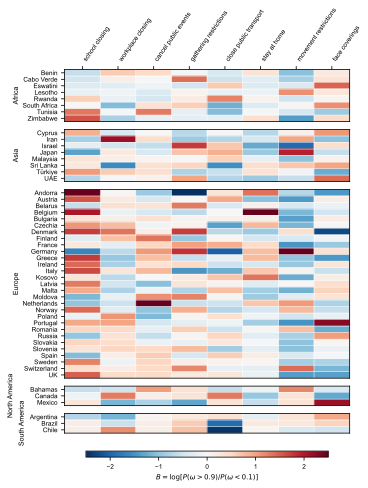

In [3]:
fig = plot_manuscript_policy_weights(summary, countries_by_cont)
display(fig)

In [5]:
fig.savefig("figure_8.svg", bbox_inches="tight")